# Retail Customer Feedback Analysis — Sentiment Classification of Product Reviews

**BC3415 Individual Assignment · Option A (Coding-Based Submission)**

## Business problem
A major online retailer receives **thousands of product reviews every day**. Reading them manually is impossible, yet they contain
the most direct signal of what customers love and hate. The company wants to automatically **classify each review as
`positive`, `neutral` or `negative`**, and turn that into **actionable product insights**.

## What this notebook delivers
| # | Section | What it shows |
|---|---------|---------------|
| 1 | Setup & configuration | One `CONFIG` dict controls the whole pipeline (reusability) |
| 2 | Data loading & labelling | 210k real Amazon reviews, star rating → sentiment |
| 3 | Exploratory data analysis | Class balance, review length, typical vocabulary |
| 4 | Preprocessing pipeline | Cleaning, contraction expansion, negation handling — with an ablation study measuring what each step adds |
| 5 | Classical baselines | TF-IDF + Naive Bayes / Logistic Regression / Linear SVM |
| 6 | Explainability (classical) | Which words drive each sentiment, and per-review explanations |
| 7 | Transformer model | Fine-tuned **DistilBERT** (HuggingFace) with class-weighted loss |
| 8 | Model comparison & error analysis | Accuracy, macro-F1, speed; where & why models fail |
| 9 | **Business insights** | Aspect-level sentiment ("pain-point map"), complaint topic discovery, rating–text mismatch detector, urgent-issue triage queue |
| 10 | Reusable inference tool | `ReviewAnalyzer` class + batch CSV scoring for new reviews |
| 11 | Conclusions & recommendations | |

> **Tip:** the fine-tuned model is saved in `models/`, so by default the notebook reuses it and runs in ~10 minutes.
> Set `CONFIG["retrain_bert"] = True` to fine-tune DistilBERT from scratch (~30 min on an Apple-silicon laptop).

## 1. Setup & configuration

In [1]:
import re
import html
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from datasets import load_dataset, Dataset
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.decomposition import NMF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import torch
import torch.nn.functional as F
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments)
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 160)

# All tunable settings live here, so the pipeline can be re-run on another dataset/model by editing one place.
CONFIG = {
    "dataset": "SetFit/amazon_reviews_multi_en",   # 200k train / 5k val / 5k test English Amazon reviews
    "seed": 42,
    "labels": ["negative", "neutral", "positive"],
    "star_to_sentiment": {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"},
    # Classical models
    "tfidf_max_features": 300_000,
    "ablation_sample": 60_000,
    # Transformer model
    "bert_checkpoint": "distilbert-base-uncased",
    "bert_train_size": 30_000,      # sub-sample so fine-tuning finishes in ~20 min on a laptop
    "bert_epochs": 2,
    "bert_max_len": 128,
    "bert_batch_size": 32,
    "bert_lr": 3e-5,
    "retrain_bert": False,          # True -> fine-tune from scratch (~30 min); False -> load the saved fine-tuned model instead of training
    # Paths
    "model_dir": Path("models"),
    "output_dir": Path("outputs"),
}
CONFIG["model_dir"].mkdir(exist_ok=True)
CONFIG["output_dir"].mkdir(exist_ok=True)

LABELS = CONFIG["labels"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
SENTIMENT_COLORS = {"negative": "#d62728", "neutral": "#9e9e9e", "positive": "#2ca02c"}

np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

W1021 15:39:57.136000 70948 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


PyTorch 2.14.1 | device: mps


## 2. Data loading & labelling

We use the English portion of the **Multilingual Amazon Reviews Corpus** (Keung et al., 2020), hosted on HuggingFace.
Every review comes with the customer's **1–5 star rating**, which we use as a (weak) sentiment label:

| Stars | Sentiment |
|-------|-----------|
| ★ – ★★ | negative |
| ★★★ | neutral |
| ★★★★ – ★★★★★ | positive |

This is a realistic setup: retailers rarely have hand-labelled sentiment, but they always have star ratings.

In [2]:
def load_reviews(dataset_name: str = CONFIG["dataset"]) -> dict:
    # Download the dataset and return {split: DataFrame} with `stars`, `sentiment` and integer `label` columns.
    raw = load_dataset(dataset_name)
    splits = {}
    for split in raw:
        df = raw[split].to_pandas()[["id", "text", "label"]]
        df["stars"] = df["label"] + 1                                   # dataset stores 0-4
        df["sentiment"] = df["stars"].map(CONFIG["star_to_sentiment"])
        df["label"] = df["sentiment"].map(LABEL2ID)
        splits[split] = df
    return splits

data = load_reviews()
train_df, val_df, test_df = data["train"], data["validation"], data["test"]

# Basic data-quality checks: empty texts and exact duplicates (duplicates inflate scores and waste compute)
for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:<10} rows={len(df):>7,}  empty={(df.text.str.strip() == '').sum():>3}  duplicates={df.text.duplicated().sum():>4}")

train_df = train_df[train_df.text.str.strip() != ""].drop_duplicates("text").reset_index(drop=True)
# Remove any training review that also appears in the test set (prevents leakage)
train_df = train_df[~train_df.text.isin(set(test_df.text))].reset_index(drop=True)
print(f"\nTraining rows after cleaning: {len(train_df):,}")
train_df.sample(5, random_state=1)[["stars", "sentiment", "text"]]

train      rows=200,000  empty=  0  duplicates= 574
validation rows=  5,000  empty=  0  duplicates=   1
test       rows=  5,000  empty=  0  duplicates=   0

Training rows after cleaning: 199,411


,stars,sentiment,text
46282,2,negative,"THE COLOR WASN'T WHITE (LOOKS WHITE HERE - SEE WHAT I MEAN?) WASN'T WORTH IT TO RETURN, SO I DONATED THEM"
15145,1,negative,Ended up trashing it
70065,2,negative,I normally wear a LG/XL depending on the shirt. I ordered an XL and they were super tight and don’t have much stretch. The XL fit more like a SM. I don’t re...
195302,5,positive,It's small but pretty handy. Fan level is sufficient and not really loud. Great when waiting in the car when ignition off. Like it's design.
61379,2,negative,Its a beautiful comforter but it ripped after I washed it.


## 3. Exploratory data analysis

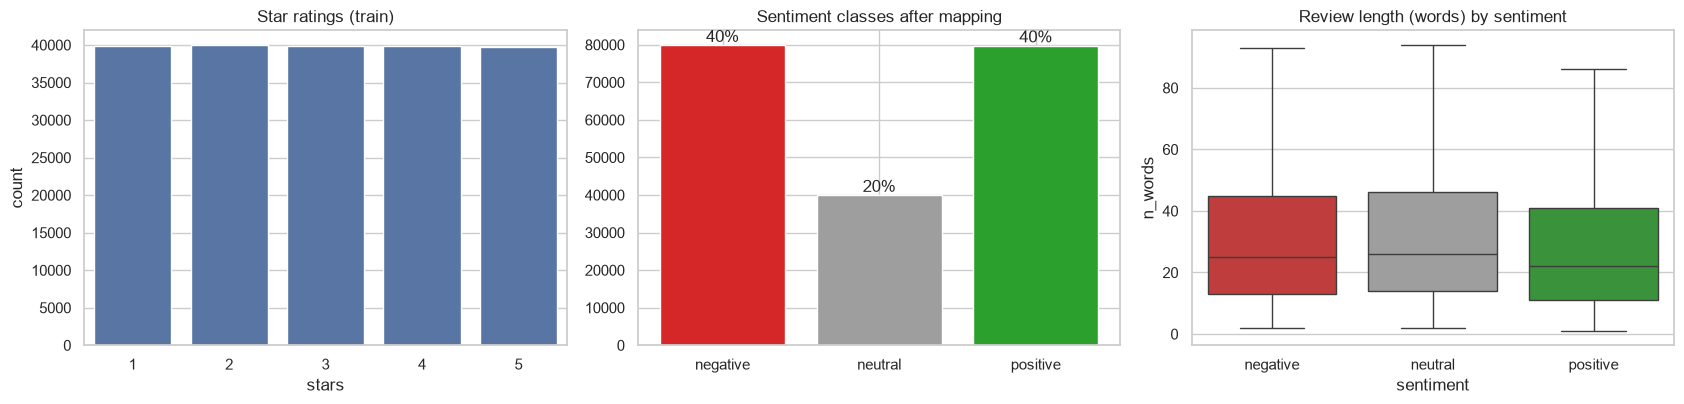

count    199411.0
mean         34.2
std          34.2
min           1.0
50%          24.0
90%          72.0
95%          96.0
99%         165.0
max         769.0


In [3]:
train_df["n_words"] = train_df.text.str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.countplot(data=train_df, x="stars", ax=axes[0], color="#4c72b0")
axes[0].set_title("Star ratings (train)")

order = train_df.sentiment.value_counts().reindex(LABELS)
axes[1].bar(LABELS, order.values, color=[SENTIMENT_COLORS[l] for l in LABELS])
for i, v in enumerate(order.values):
    axes[1].text(i, v, f"{v / order.sum():.0%}", ha="center", va="bottom")
axes[1].set_title("Sentiment classes after mapping")

sns.boxplot(data=train_df, x="sentiment", y="n_words", order=LABELS, palette=SENTIMENT_COLORS,
            showfliers=False, ax=axes[2])
axes[2].set_title("Review length (words) by sentiment")
plt.tight_layout(); plt.show()

print(train_df.n_words.describe(percentiles=[.5, .9, .95, .99]).round(1).to_string())

**Observations**
- After mapping, the classes are **imbalanced**: neutral is only 20% of reviews. Plain accuracy would reward a model that
  ignores neutral reviews, so we track **macro-F1** (average F1 across classes) as the primary metric and use class weighting.
- Negative reviews are longer — unhappy customers explain *what went wrong*, which is exactly the information the business needs.
- 95% of reviews are under ~110 words, so a 128-token limit for BERT loses very little text.

In [4]:
# A quick look at representative reviews from each class
for s in LABELS:
    print(f"--- {s.upper()} ---")
    for t in train_df[train_df.sentiment == s].text.sample(2, random_state=7):
        print("  •", t[:220])

--- NEGATIVE ---
  • Awful. It does not charge anything. Unfortunately, I just busted it out of the packaging and missed the return deadline. Save your $$$ and buy one from Walmart.
  • I like the material it’s made of and all the slots for credit cards. But I don’t like the size, it’s way smaller than what it looks like in the picture. Not big enough to hold my cell phone.
--- NEUTRAL ---
  • The colors didn't all work properly. The receiver antenna isn't very good...
  • The material of the screen protector is medium hard, I had wait 30 mins and still couldn't press the edge to settle down. I tried 2 times before give up. I watch the youtube but it seems like there screen protector in th
--- POSITIVE ---
  • I currently use this for my iPhone 8. Great fit. Not too bulky, but slightly heavy. The battery recharges pretty fast when the case is turned on. Lately, I’ve been running out of battery so this has come in very handy!!
  • The Roomba 980 performs as stated. Excellent pick up and

## 4. Preprocessing pipeline

Raw reviews are noisy: HTML entities, URLs, shouting ("TERRIBLE!!!"), elongated words ("sooooo"), and contractions.
The `clean_text` pipeline below normalises them **step by step**. Two design choices are specific to sentiment:

1. **We do *not* remove stop-words.** Standard stop-word lists contain *not, no, never, very, but* — words that flip or
   intensify sentiment. Removing them destroys signal ("*not* good" → "good").
2. **Negation marking.** Words that follow a negation (until the next punctuation) get a `neg_` prefix, so
   "not worth the money" becomes `not neg_worth neg_the neg_money`. A bag-of-words model can then tell
   "worth it" (positive) apart from "not worth it" (negative).

> Transformers like DistilBERT understand context natively, so for BERT we only apply the light `basic_clean`
> step (HTML/URL/whitespace) and let its own tokenizer handle the rest.

In [5]:
CONTRACTIONS = {
    r"won't": "will not", r"can't": "can not", r"n't": " not", r"'re": " are", r"'s": "",
    r"'d": " would", r"'ll": " will", r"'ve": " have", r"'m": " am",
}
NEGATIONS = r"\b(?:not|no|never|nothing|nobody|none|nor|cannot|without)\b"


def basic_clean(text: str) -> str:
    # Step 1 - light cleaning safe for any model: decode HTML, drop tags/URLs, collapse whitespace.
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)                       # HTML tags such as <br />
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)     # links
    return re.sub(r"\s+", " ", text).strip()


def normalise(text: str) -> str:
    # Step 2 - lowercase, expand contractions, shorten elongations, keep !/? as sentiment tokens.
    text = text.lower().replace("’", "'")
    for pattern, repl in CONTRACTIONS.items():
        text = re.sub(pattern, repl, text)
    text = re.sub(r"(\w)\1{2,}", r"\1\1", text)                # "sooooo" -> "soo"
    text = re.sub(r"!+", " ! ", text)                          # "!!!" is a strong signal: keep as a token
    text = re.sub(r"\?+", " ? ", text)
    text = re.sub(r"\d+", " num ", text)                       # numbers rarely carry sentiment by themselves
    text = re.sub(r"[^a-z!?.,;:_ ]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def mark_negation(text: str) -> str:
    # Step 3 - prefix neg_ to words in the scope of a negation (scope ends at punctuation).
    out, negated = [], False
    for tok in re.findall(r"[a-z_]+|[!?.,;:]", text):
        if tok in "!?.,;:":
            negated = False
            out.append(tok)
        elif re.fullmatch(NEGATIONS, tok):
            negated = True
            out.append(tok)
        else:
            out.append(f"neg_{tok}" if negated else tok)
    return " ".join(out)


def clean_text(text: str, negation: bool = True) -> str:
    # Full pipeline used by the classical (TF-IDF) models.
    text = normalise(basic_clean(text))
    return mark_negation(text) if negation else text


# Demonstrate each step on a deliberately messy example
example = "I'm sooooo disappointed!!! It's NOT worth the $45, broke after 2 days.<br />See https://amzn.to/x"
for step, fn in [("raw", lambda t: t), ("basic_clean", basic_clean),
                 ("+ normalise", lambda t: normalise(basic_clean(t))), ("+ negation", clean_text)]:
    print(f"{step:<13}| {fn(example)}")

raw          | I'm sooooo disappointed!!! It's NOT worth the $45, broke after 2 days.<br />See https://amzn.to/x
basic_clean  | I'm sooooo disappointed!!! It's NOT worth the $45, broke after 2 days. See URL
+ normalise  | i am soo disappointed ! it not worth the num , broke after num days. see url
+ negation   | i am soo disappointed ! it not neg_worth neg_the neg_num , broke after num days . see url


In [6]:
%%time
# Apply the pipeline to every split once and cache the result
for df in (train_df, val_df, test_df):
    df["clean"] = df.text.map(clean_text)
    df["clean_noneg"] = df.text.map(lambda t: clean_text(t, negation=False))
train_df[["text", "clean"]].head(3)

CPU times: user 14.2 s, sys: 86.2 ms, total: 14.3 s
Wall time: 14.3 s


,text,clean
0,"Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged the ent...","arrived broken . manufacturer defect . two of the legs of the base were not neg_completely neg_formed , so there was no neg_way neg_to neg_insert neg_the ne..."
1,the cabinet dot were all detached from backing... got me,the cabinet dot were all detached from backing . . . got me
2,I received my first order of this product and it was broke so I ordered it again. The second one was broke in more places than the first. I can't blame the ...,i received my first order of this product and it was broke so i ordered it again . the second one was broke in more places than the first . i can not neg_bl...


### 4.1 Ablation study — does each preprocessing step actually help?
Rather than assuming preprocessing helps, we **measure** it: the same TF-IDF + Logistic Regression model is trained on
raw text, after cleaning, and after cleaning + negation marking, and scored on the validation set.

In [7]:
abl_train = train_df.sample(CONFIG["ablation_sample"], random_state=CONFIG["seed"])
variants = {
    "raw text (lowercase only)": ("text", "text"),
    "+ cleaning & normalisation": ("clean_noneg", "clean_noneg"),
    "+ negation marking": ("clean", "clean"),
}
ablation = []
for name, (tr_col, va_col) in variants.items():
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True,
                          token_pattern=r"(?u)\b\w+\b|[!?]")
    clf = LogisticRegression(C=2, max_iter=2000, class_weight="balanced")
    clf.fit(vec.fit_transform(abl_train[tr_col]), abl_train.label)
    pred = clf.predict(vec.transform(val_df[va_col]))
    ablation.append({"preprocessing": name, "accuracy": accuracy_score(val_df.label, pred),
                     "macro_F1": f1_score(val_df.label, pred, average="macro")})
pd.DataFrame(ablation).style.format({"accuracy": "{:.4f}", "macro_F1": "{:.4f}"}).highlight_max(
    subset=["accuracy", "macro_F1"], color="#c6efce")

,preprocessing,accuracy,macro_F1
0,raw text (lowercase only),0.7088,0.6675
1,+ cleaning & normalisation,0.7080,0.6652
2,+ negation marking,0.7132,0.6717


**Result.** Generic cleaning on its own makes almost no difference (TF-IDF with `sublinear_tf` is already robust to
noise), but **negation marking gives the best score** on both metrics. This confirms that handling negation is the
sentiment-specific step that matters, while the cleaning steps mainly make the vocabulary smaller and more readable for
the explainability section. We keep the full pipeline.

## 5. Classical baselines: TF-IDF + linear models

**TF-IDF** turns each review into a sparse vector of word and word-pair (bigram) weights; bigrams capture phrases such as
"*waste money*" or "*highly recommend*". We then compare three fast, interpretable classifiers trained on the full ~200k reviews:

- **Complement Naive Bayes** — the classic text-classification baseline (Complement NB is the variant designed for imbalanced classes).
- **Logistic Regression** — linear model producing calibrated probabilities; regularisation `C` is tuned on the validation set.
- **Linear SVM** — strong margin-based linear classifier.

All models use `class_weight="balanced"` (or equivalent) so the minority neutral class is not ignored.

In [8]:
RESULTS = []          # every model's test metrics are collected here for the final comparison


def evaluate(name: str, y_true, y_pred, train_time: float, infer_time: float, show: bool = True) -> dict:
    # Compute metrics, print a classification report, plot a confusion matrix, and log results.
    res = {"model": name,
           "accuracy": accuracy_score(y_true, y_pred),
           "macro_F1": f1_score(y_true, y_pred, average="macro"),
           **{f"F1_{l}": f for l, f in zip(LABELS, f1_score(y_true, y_pred, average=None))},
           "train_time_s": train_time,
           "ms_per_1k_reviews": infer_time / len(y_true) * 1000 * 1000}
    RESULTS[:] = [r for r in RESULTS if r["model"] != name] + [res]
    if show:
        print(f"=== {name} ===")
        print(classification_report(y_true, y_pred, target_names=LABELS, digits=3))
        fig, ax = plt.subplots(figsize=(4.4, 3.8))
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"), display_labels=LABELS).plot(
            ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
        ax.set_title(f"{name}\n(row-normalised: recall per class)", fontsize=10)
        plt.show()
    return res

In [9]:
%%time
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True,
                        max_features=CONFIG["tfidf_max_features"], token_pattern=r"(?u)\b\w+\b|[!?]")
X_train = tfidf.fit_transform(train_df.clean)
X_val, X_test = tfidf.transform(val_df.clean), tfidf.transform(test_df.clean)
y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values
print("TF-IDF matrix:", X_train.shape)

# Tune the regularisation strength of Logistic Regression on the validation set
tuning = {}
for C in [0.5, 1, 2, 4]:
    m = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(X_train, y_train)
    tuning[C] = f1_score(y_val, m.predict(X_val), average="macro")
    print(f"  C={C:<4} validation macro-F1 = {tuning[C]:.4f}")
BEST_C = max(tuning, key=tuning.get)
print("Best C:", BEST_C)

TF-IDF matrix: (199411, 259996)


  C=0.5  validation macro-F1 = 0.6882


  C=1    validation macro-F1 = 0.6888


  C=2    validation macro-F1 = 0.6809


  C=4    validation macro-F1 = 0.6772
Best C: 1
CPU times: user 1min 44s, sys: 5.55 s, total: 1min 50s
Wall time: 1min 51s


=== TF-IDF + Complement NB ===
              precision    recall  f1-score   support

    negative      0.720     0.828     0.770      2000
     neutral      0.436     0.202     0.276      1000
    positive      0.764     0.855     0.807      2000

    accuracy                          0.713      5000
   macro avg      0.640     0.628     0.618      5000
weighted avg      0.681     0.713     0.686      5000



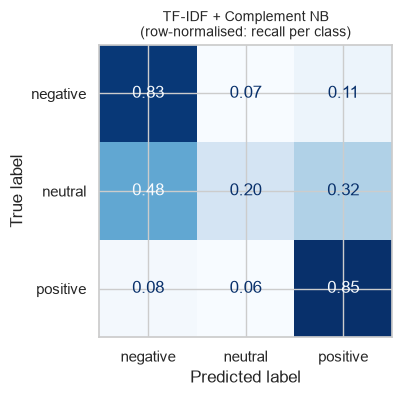

=== TF-IDF + Logistic Regression ===
              precision    recall  f1-score   support

    negative      0.798     0.758     0.778      2000
     neutral      0.414     0.523     0.462      1000
    positive      0.858     0.788     0.822      2000

    accuracy                          0.723      5000
   macro avg      0.690     0.690     0.687      5000
weighted avg      0.745     0.723     0.732      5000



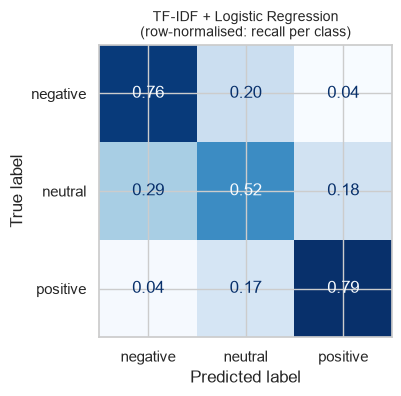

=== TF-IDF + Linear SVM ===
              precision    recall  f1-score   support

    negative      0.764     0.820     0.791      2000
     neutral      0.432     0.374     0.401      1000
    positive      0.830     0.825     0.827      2000

    accuracy                          0.733      5000
   macro avg      0.675     0.673     0.673      5000
weighted avg      0.724     0.733     0.728      5000



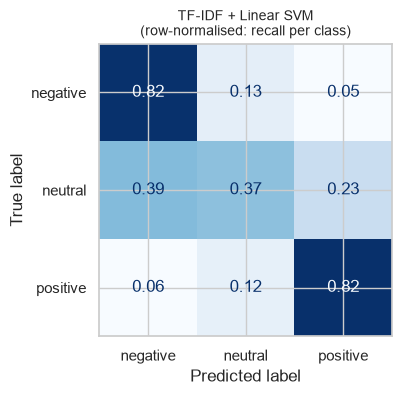

['models/tfidf_logreg.joblib']

In [10]:
classical_models = {
    "TF-IDF + Complement NB": ComplementNB(alpha=0.3),
    "TF-IDF + Logistic Regression": LogisticRegression(C=BEST_C, max_iter=3000, class_weight="balanced"),
    "TF-IDF + Linear SVM": LinearSVC(C=0.1, class_weight="balanced"),
}
for name, model in classical_models.items():
    t0 = time.time(); model.fit(X_train, y_train); train_t = time.time() - t0
    t0 = time.time(); pred = model.predict(tfidf.transform(test_df.clean)); infer_t = time.time() - t0
    evaluate(name, y_test, pred, train_t, infer_t)

logreg = classical_models["TF-IDF + Logistic Regression"]
joblib.dump({"tfidf": tfidf, "model": logreg}, CONFIG["model_dir"] / "tfidf_logreg.joblib")

## 6. Explainability of the classical model

A key advantage of a linear model is **transparency**: every word has a learned weight per class.
Below are the words and phrases that push a review most strongly towards each sentiment.
Notice the `neg_` features learned through negation marking (e.g. `neg_recommend` is a strong negative signal).

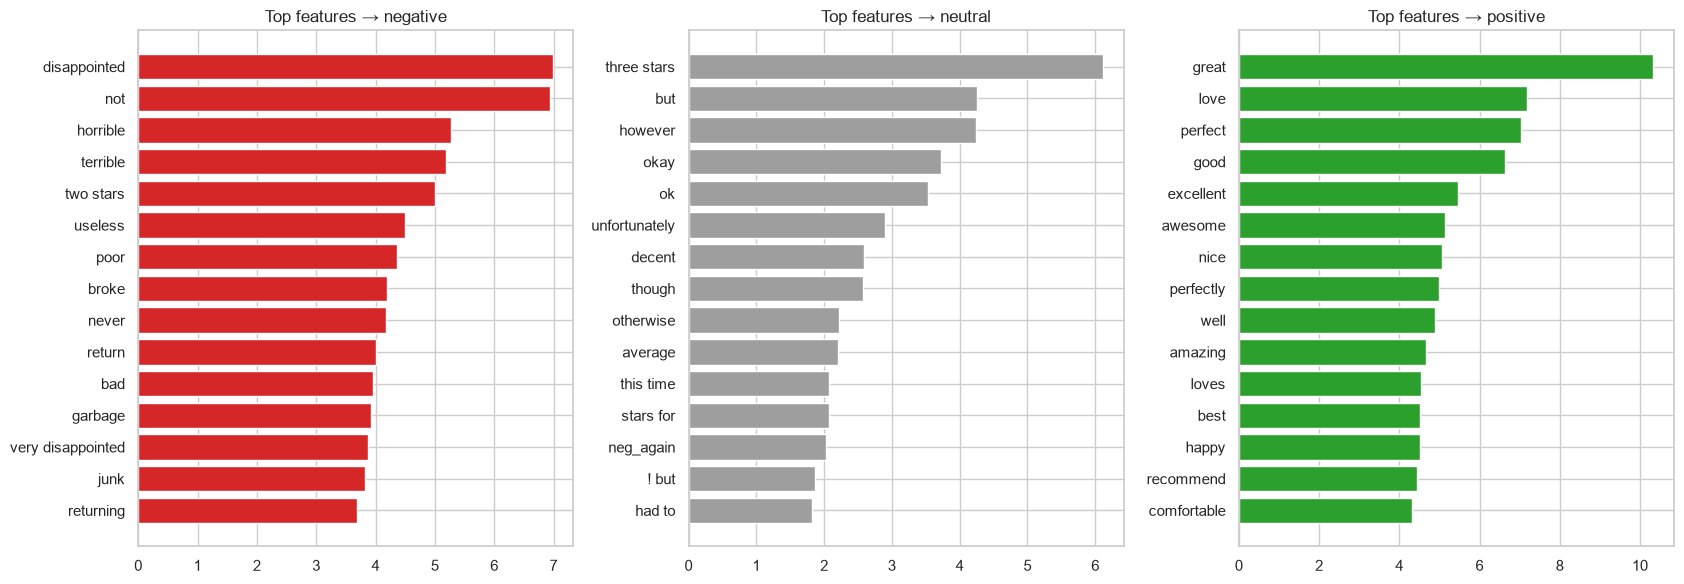

In [11]:
feature_names = np.array(tfidf.get_feature_names_out())
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (i, label) in zip(axes, enumerate(LABELS)):
    top = np.argsort(logreg.coef_[i])[-15:]
    ax.barh(feature_names[top], logreg.coef_[i][top], color=SENTIMENT_COLORS[label])
    ax.set_title(f"Top features → {label}")
plt.tight_layout(); plt.show()

In [12]:
def explain_linear(text: str, top_k: int = 8) -> pd.DataFrame:
    # Per-review explanation: contribution of each feature = TF-IDF weight x class coefficient.
    x = tfidf.transform([clean_text(text)])
    proba = logreg.predict_proba(x)[0]
    pred = int(proba.argmax())
    idx = x.nonzero()[1]
    contrib = x.data * logreg.coef_[pred][idx]
    order = np.argsort(-np.abs(contrib))[:top_k]
    print(f"Prediction: {LABELS[pred]}  (p={proba[pred]:.2f})  |  "
          + "  ".join(f"{l}={p:.2f}" for l, p in zip(LABELS, proba)))
    return pd.DataFrame({"feature": feature_names[idx][order], "contribution": contrib[order].round(3)})

explain_linear("The screen looks great but the battery is not good and customer service never replied.")

Prediction: negative  (p=0.74)  |  negative=0.74  neutral=0.22  positive=0.04


,feature,contribution
0,great,-0.772
1,never,0.546
2,not,0.359
3,great but,0.286
4,not neg_good,0.255
5,the screen,0.198
6,neg_and,0.140
7,screen,0.129


## 7. Transformer model: fine-tuning DistilBERT

Bag-of-words models ignore word order and context. **DistilBERT** (Sanh et al., 2019) is a 66M-parameter distilled version
of BERT that keeps ~97% of BERT's language understanding while being 60% faster — a good fit for high-volume review streams.

Training choices:
- **Stratified sub-sample** of 30k reviews (configurable) so it trains in ~20 minutes on a laptop GPU (Apple MPS).
- **Class-weighted cross-entropy** so the model pays more attention to the minority neutral class.
- **Dynamic padding** (pad each batch only to its longest review) for speed.
- Best checkpoint selected by **validation macro-F1**.

In [13]:
BERT_DIR = CONFIG["model_dir"] / "distilbert-sentiment"

bert_train, _ = train_test_split(train_df, train_size=CONFIG["bert_train_size"], stratify=train_df.label,
                                 random_state=CONFIG["seed"])
bert_val = val_df.sample(2000, random_state=CONFIG["seed"])  # smaller eval set keeps per-epoch evaluation fast
print("BERT training set:", bert_train.sentiment.value_counts().to_dict())

tokenizer = AutoTokenizer.from_pretrained(BERT_DIR if (BERT_DIR.exists() and not CONFIG["retrain_bert"])
                                          else CONFIG["bert_checkpoint"])


def to_hf_dataset(df: pd.DataFrame) -> Dataset:
    # Convert a DataFrame into a tokenised HuggingFace Dataset (BERT gets only light cleaning).
    ds = Dataset.from_dict({"text": df.text.map(basic_clean).tolist(), "label": df.label.tolist()})
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=CONFIG["bert_max_len"]),
                  batched=True, remove_columns=["text"])


class WeightedTrainer(Trainer):
    # HuggingFace Trainer with class-weighted cross-entropy to counter class imbalance.
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = F.cross_entropy(outputs.logits, labels, weight=self.class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds), "macro_f1": f1_score(labels, preds, average="macro")}

BERT training set: {'negative': 12007, 'positive': 11990, 'neutral': 6003}


Loaded fine-tuned model from models/distilbert-sentiment (original training time 30.9 min)


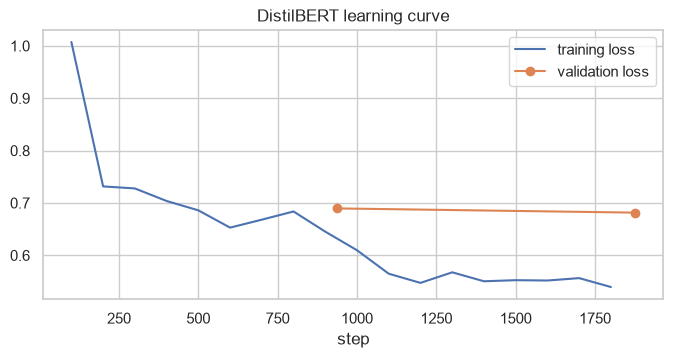

,epoch,eval_loss,eval_accuracy,eval_macro_f1
9,1.0,0.689575,0.7325,0.691758
19,2.0,0.681532,0.7230,0.696295


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [14]:
if CONFIG["retrain_bert"] or not BERT_DIR.exists():
    counts = np.bincount(bert_train.label, minlength=len(LABELS))
    class_weights = torch.tensor(len(bert_train) / (len(LABELS) * counts), dtype=torch.float)
    print("Class weights:", dict(zip(LABELS, class_weights.numpy().round(2))))

    bert_model = AutoModelForSequenceClassification.from_pretrained(
        CONFIG["bert_checkpoint"], num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id=LABEL2ID)

    steps_per_epoch = int(np.ceil(len(bert_train) / CONFIG["bert_batch_size"]))
    args = TrainingArguments(
        output_dir=str(CONFIG["model_dir"] / "bert_checkpoints"),
        num_train_epochs=CONFIG["bert_epochs"],
        per_device_train_batch_size=CONFIG["bert_batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=CONFIG["bert_lr"],
        weight_decay=0.01,
        warmup_steps=int(0.06 * steps_per_epoch * CONFIG["bert_epochs"]),
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        logging_steps=100,
        report_to="none",
        seed=CONFIG["seed"],
        disable_tqdm=True,
    )
    trainer = WeightedTrainer(
        model=bert_model, args=args,
        train_dataset=to_hf_dataset(bert_train), eval_dataset=to_hf_dataset(bert_val),
        processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics, class_weights=class_weights)

    t0 = time.time()
    trainer.train()
    BERT_TRAIN_TIME = time.time() - t0
    trainer.save_model(str(BERT_DIR)); tokenizer.save_pretrained(str(BERT_DIR))
    (BERT_DIR / "train_time.txt").write_text(f"{BERT_TRAIN_TIME:.1f}")
    pd.Series(trainer.state.log_history).to_json(BERT_DIR / "train_log.json", orient="values")
    print(f"Training finished in {BERT_TRAIN_TIME / 60:.1f} min")
else:
    BERT_TRAIN_TIME = float((BERT_DIR / "train_time.txt").read_text())
    print(f"Loaded fine-tuned model from {BERT_DIR} (original training time {BERT_TRAIN_TIME / 60:.1f} min)")

# Learning curve from the saved training log
log = pd.read_json(BERT_DIR / "train_log.json")
fig, ax = plt.subplots(figsize=(8, 3.5))
if "loss" in log:
    log.dropna(subset=["loss"]).plot(x="step", y="loss", ax=ax, label="training loss")
log.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=ax, marker="o", label="validation loss")
ax.set_title("DistilBERT learning curve"); plt.show()
display(log.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]])

bert_model = AutoModelForSequenceClassification.from_pretrained(BERT_DIR).to(DEVICE).eval()

=== DistilBERT (fine-tuned) ===
              precision    recall  f1-score   support

    negative      0.818     0.746     0.781      2000
     neutral      0.411     0.564     0.476      1000
    positive      0.886     0.800     0.841      2000

    accuracy                          0.731      5000
   macro avg      0.705     0.704     0.699      5000
weighted avg      0.764     0.731     0.744      5000



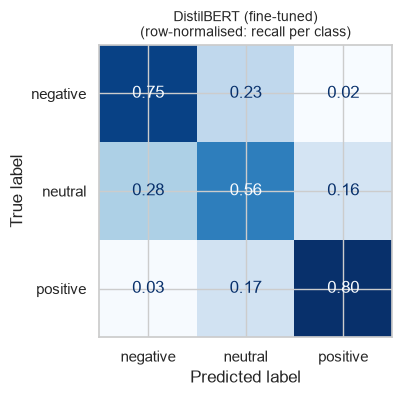

In [15]:
@torch.no_grad()
def bert_predict_proba(texts, batch_size: int = 64) -> np.ndarray:
    # Batched inference returning class probabilities. Texts are sorted by length so batches need little padding.
    texts = [basic_clean(t) for t in texts]
    order = np.argsort([len(t) for t in texts])
    probs = np.zeros((len(texts), len(LABELS)), dtype=np.float32)
    for start in range(0, len(texts), batch_size):
        idx = order[start:start + batch_size]
        enc = tokenizer([texts[i] for i in idx], truncation=True, max_length=CONFIG["bert_max_len"],
                        padding=True, return_tensors="pt").to(DEVICE)
        probs[idx] = torch.softmax(bert_model(**enc).logits, dim=-1).float().cpu().numpy()
    return probs

t0 = time.time()
test_proba_bert = bert_predict_proba(test_df.text.tolist())
infer_t = time.time() - t0
test_df["bert_pred"] = test_proba_bert.argmax(1)
test_df["bert_conf"] = test_proba_bert.max(1)
evaluate("DistilBERT (fine-tuned)", y_test, test_df.bert_pred, BERT_TRAIN_TIME, infer_t);

### 7.1 Explaining the transformer: occlusion analysis
Transformers are less transparent than linear models. A simple, model-agnostic way to explain a prediction is
**occlusion**: remove one word at a time and measure how much the predicted probability drops.
Words whose removal changes the prediction most are the ones the model relied on.

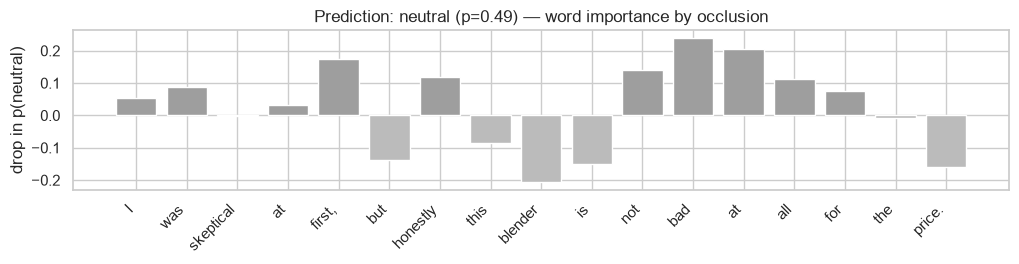

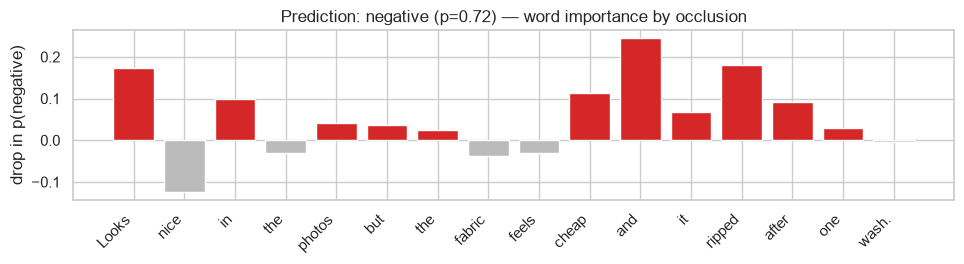

In [16]:
def explain_bert(text: str):
    # Leave-one-word-out importance for the predicted class of a single review.
    words = text.split()
    base = bert_predict_proba([text])[0]
    pred = int(base.argmax())
    variants = [" ".join(words[:i] + words[i + 1:]) for i in range(len(words))]
    drops = base[pred] - bert_predict_proba(variants)[:, pred]
    fig, ax = plt.subplots(figsize=(min(1 + 0.55 * len(words), 16), 2.8))
    ax.bar(range(len(words)), drops, color=[SENTIMENT_COLORS[LABELS[pred]] if d > 0 else "#bbbbbb" for d in drops])
    ax.set_xticks(range(len(words))); ax.set_xticklabels(words, rotation=45, ha="right")
    ax.set_ylabel(f"drop in p({LABELS[pred]})")
    ax.set_title(f"Prediction: {LABELS[pred]} (p={base[pred]:.2f}) — word importance by occlusion")
    plt.tight_layout(); plt.show()

explain_bert("I was skeptical at first, but honestly this blender is not bad at all for the price.")
explain_bert("Looks nice in the photos but the fabric feels cheap and it ripped after one wash.")

## 8. Model comparison & error analysis

,accuracy,macro_F1,F1_negative,F1_neutral,F1_positive,train_time_s,ms_per_1k_reviews
model,,,,,,,
TF-IDF + Complement NB,0.713,0.618,0.770,0.276,0.807,0.0,30
TF-IDF + Linear SVM,0.733,0.673,0.791,0.401,0.827,2.5,31
TF-IDF + Logistic Regression,0.723,0.687,0.778,0.462,0.822,25.5,32
DistilBERT (fine-tuned),0.731,0.699,0.781,0.476,0.841,1852.4,2373


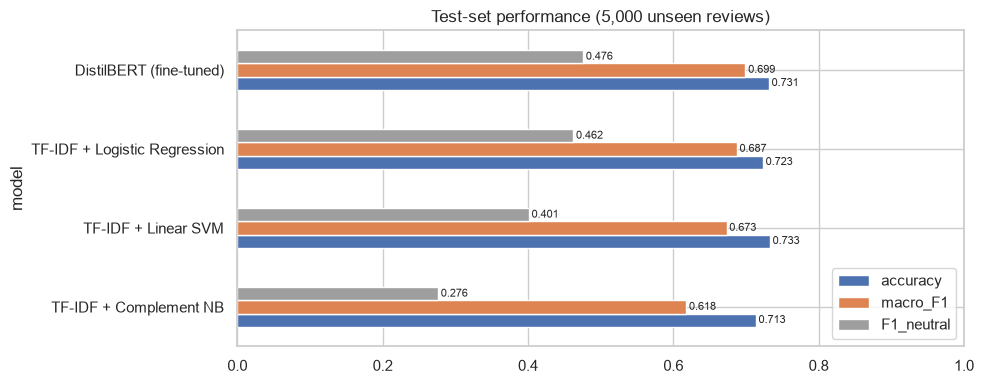

In [17]:
results_df = pd.DataFrame(RESULTS).set_index("model").sort_values("macro_F1")
display(results_df.style.format({c: "{:.3f}" for c in results_df.columns if c.startswith(("acc", "macro", "F1"))}
                                | {"train_time_s": "{:.1f}", "ms_per_1k_reviews": "{:.0f}"})
        .highlight_max(subset=["accuracy", "macro_F1", "F1_negative", "F1_neutral", "F1_positive"], color="#c6efce"))

fig, ax = plt.subplots(figsize=(10, 4))
results_df[["accuracy", "macro_F1", "F1_neutral"]].plot.barh(ax=ax, color=["#4c72b0", "#dd8452", "#9e9e9e"])
ax.set_xlim(0, 1); ax.set_title("Test-set performance (5,000 unseen reviews)"); ax.legend(loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()

**Error analysis.** The hardest class is **neutral** for every model. Is that a model weakness or a data problem?
Looking at confidently-wrong predictions shows that many "errors" are actually **label noise**: a 3-star rating does not
always mean neutral text, and some customers give 1 star to a review that reads positively (e.g. a delivery problem).

In [18]:
test_df["bert_label"] = test_df.bert_pred.map(dict(enumerate(LABELS)))
errors = test_df[test_df.bert_pred != test_df.label]
print("Where DistilBERT's mistakes come from (true → predicted):")
print(pd.crosstab(errors.sentiment, errors.bert_label).to_string(), "\n")

# How often does the model confuse the two *opposite* sentiments? (the costly mistake for the business)
polar = test_df[test_df.sentiment != "neutral"]
flipped = ((polar.sentiment == "positive") & (polar.bert_label == "negative") |
           (polar.sentiment == "negative") & (polar.bert_label == "positive")).sum()
print(f"Positive/negative confused with each other: {flipped} of {len(polar):,} polar reviews "
      f"({flipped / len(polar):.1%}) — almost all errors involve the ambiguous neutral class.\n")
print("Most confident mistakes:")
errors.nlargest(6, "bert_conf")[["stars", "sentiment", "bert_label", "bert_conf", "text"]].round(2)

Where DistilBERT's mistakes come from (true → predicted):
bert_label  negative  neutral  positive
sentiment                              
negative           0      462        46
neutral          277        0       159
positive          54      345         0 

Positive/negative confused with each other: 100 of 4,000 polar reviews (2.5%) — almost all errors involve the ambiguous neutral class.

Most confident mistakes:


,stars,sentiment,bert_label,bert_conf,text
2713,3,neutral,positive,0.99,My son loves this watch very much. No problem with it. He loves all the features.
2856,3,neutral,positive,0.98,"Great must-have tool! A long time ago I was able to open some of my watches, but some were so tight, that it was almost impossible to avoid scratches. This ..."
2814,3,neutral,positive,0.98,I love it and can’t wait to wear it. It looks just like the picture
321,1,negative,positive,0.98,"Fantastic belt ,love it . This is my second one , the first one was a little small but this one is perfect. I suggest you order one size bigger than your wa..."
1181,2,negative,positive,0.98,Love this drink. Does give me energy when needed and no crash. Will be ordering more.
2011,3,neutral,positive,0.98,"Can't complain for price, product is a light fragrance not too heavy, great for your travel bag, great thing about this brand is they have several different..."


## 9. Turning predictions into business insights

A sentiment label per review is only the first step. Product and operations teams need to know **what** customers are
unhappy about, **which** reviews need action today, and **where** star ratings are misleading.
We combine the classifier with four lightweight text-analytics techniques:

1. **Aspect-based sentiment ("pain-point map")** — split each review into sentences, detect which business aspect each
   sentence talks about (quality, price, delivery, size …), and classify the *sentence* with DistilBERT. A review like
   *"Love the colour, but delivery took 3 weeks"* then counts as positive for *appearance* and negative for *delivery*.
2. **Complaint topic discovery** — unsupervised NMF topic modelling on negative reviews surfaces recurring problems
   without any predefined list.
3. **Rating–text mismatch detector** — reviews whose text sentiment strongly contradicts the star rating.
4. **Urgent-issue triage queue** — negative reviews mentioning safety, defects or fraud are ranked for escalation.

In [19]:
# Aspect lexicon: keyword patterns that signal which part of the customer experience a sentence is about.
ASPECTS = {
    "Quality / durability": r"quality|broke|broken|break|durable|flimsy|sturdy|cheaply made|fell apart|stopped working|defect\w*|lasted|last long",
    "Price / value": r"price|value|worth|expensive|overpriced|money|cheap(?!ly)|deal|cost",
    "Delivery / shipping": r"shipping|shipped|delivery|delivered|arrived|arrive|late|on time|took \w+ (?:days|weeks)",
    "Packaging": r"packag\w*|box|wrapped|seal\w*",
    "Size / fit": r"size|sizing|fit|fits|too small|too big|too large|tight|loose|runs small|runs large",
    "Ease of use / setup": r"easy to|install\w*|set ?up|instructions?|assembl\w*|user friendly|complicated",
    "Customer service / returns": r"customer service|seller|refund\w*|return\w*|replacement|warranty|customer support|tech support|contacted",
    "Battery / power": r"batter\w*|charg(?:e|er|ers|es|ing)|power",
    "Appearance / design": r"colou?rs?|looks|looked|design|pictur\w*|photo|style|pretty|beautiful|ugly",
    "Comfort / feel": r"comfortable|comfort|uncomfortable|soft|itchy|scratchy",
}
ASPECT_RE = {a: re.compile(rf"\b(?:{p})\b", re.I) for a, p in ASPECTS.items()}


def split_sentences(text: str) -> list:
    return [s for s in re.split(r"(?<=[.!?;])\s+|\s+but\s+", basic_clean(text)) if len(s.split()) >= 3]


def detect_aspects(sentence: str) -> list:
    return [a for a, rx in ASPECT_RE.items() if rx.search(sentence)]


# Build a sentence-level table for the test reviews and classify every aspect-bearing sentence with DistilBERT
rows = [{"review_id": rid, "sentence": s, "aspect": a}
        for rid, text in zip(test_df.id, test_df.text)
        for s in split_sentences(text) for a in detect_aspects(s)]
aspect_df = pd.DataFrame(rows)
uniq = aspect_df.sentence.unique()
sent_pred = dict(zip(uniq, bert_predict_proba(list(uniq)).argmax(1)))
aspect_df["sentiment"] = aspect_df.sentence.map(sent_pred).map(dict(enumerate(LABELS)))
print(f"{len(aspect_df):,} aspect mentions found in {aspect_df.review_id.nunique():,} of {len(test_df):,} reviews")

5,409 aspect mentions found in 2,912 of 5,000 reviews


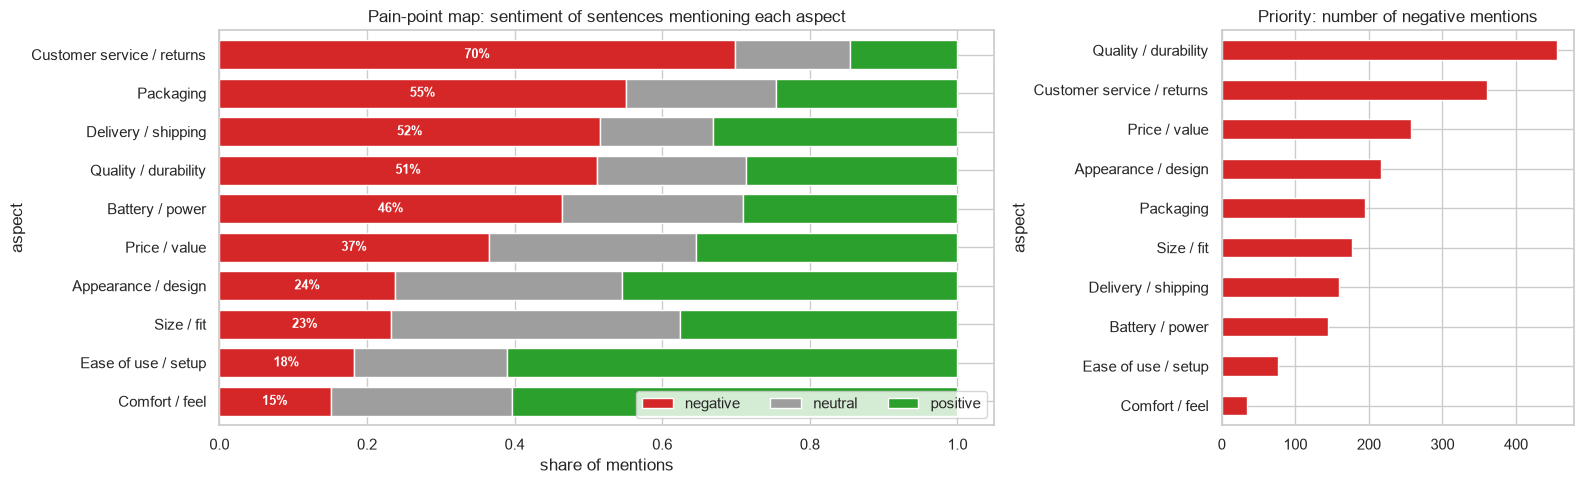

In [20]:
summary = (aspect_df.groupby("aspect").sentiment.value_counts(normalize=True).unstack().reindex(columns=LABELS).fillna(0))
summary["mentions"] = aspect_df.groupby("aspect").size()
summary = summary.sort_values("negative")

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
summary[LABELS].plot.barh(stacked=True, ax=axes[0], color=[SENTIMENT_COLORS[l] for l in LABELS], width=0.75)
axes[0].set_title("Pain-point map: sentiment of sentences mentioning each aspect"); axes[0].set_xlabel("share of mentions")
axes[0].legend(loc="lower right", ncol=3)
for i, v in enumerate(summary.negative):
    axes[0].text(v / 2, i, f"{v:.0%}", va="center", ha="center", color="white", fontsize=9, fontweight="bold")

# Priority = how often an aspect is mentioned x how negative it is (the number of unhappy mentions)
summary["negative_mentions"] = (summary.negative * summary.mentions).round()
summary.sort_values("negative_mentions").negative_mentions.plot.barh(ax=axes[1], color=SENTIMENT_COLORS["negative"])
axes[1].set_title("Priority: number of negative mentions")
plt.tight_layout(); plt.show()

In [21]:
# Evidence for the decision-maker: real customer quotes behind the top pain points
for aspect in summary.sort_values("negative_mentions").index[::-1][:3]:
    print(f"\n### {aspect}")
    quotes = aspect_df[(aspect_df.aspect == aspect) & (aspect_df.sentiment == "negative")].sentence
    for q in quotes.sample(min(3, len(quotes)), random_state=3):
        print("  “" + q[:180] + "”")


### Quality / durability
  “They stopped working on March 26, 2018.”
  “Very flimsy quality!”
  “Mine broke into a million shards.”

### Customer service / returns
  “Unfortunately, There’s no other way for me to complain about this problem and ask for a refund/replacement other than through writing this review which is a shame because I really ”
  “This product arrived late and no return policy.”
  “With a no return policy I can’t even get a replacement.”

### Price / value
  “Sadly, really doesn't seem to work worth a darn.”
  “Don't waste your money”
  “It is a regular charging port not worth the purchase”


### 9.2 Complaint topic discovery (unsupervised)

In [22]:
# NMF on TF-IDF of reviews predicted negative: each topic is a recurring complaint theme
neg_reviews = test_df[test_df.bert_label == "negative"]
# Generic review words (and the `num` placeholder) are removed so topics show the *content* of complaints
TOPIC_STOPWORDS = list(ENGLISH_STOP_WORDS | {"num", "did", "does", "product", "item", "just", "use", "used",
                                             "got", "like", "really", "would", "buy", "bought", "one", "get"})
topic_vec = TfidfVectorizer(stop_words=TOPIC_STOPWORDS, ngram_range=(1, 2), min_df=5, max_df=0.5)
X_neg = topic_vec.fit_transform(neg_reviews.text.map(lambda t: normalise(basic_clean(t))))
nmf = NMF(n_components=8, random_state=CONFIG["seed"], init="nndsvda", max_iter=500).fit(X_neg)
terms = topic_vec.get_feature_names_out()
topic_share = np.bincount(nmf.transform(X_neg).argmax(1), minlength=8) / X_neg.shape[0]

topics = pd.DataFrame({
    "top terms": [", ".join(terms[np.argsort(c)[-8:][::-1]]) for c in nmf.components_],
    "share of negative reviews": topic_share,
}).sort_values("share of negative reviews", ascending=False)
topics.index = [f"Topic {i + 1}" for i in range(len(topics))]
topics.style.format({"share of negative reviews": "{:.1%}"}).bar(subset=["share of negative reviews"], color="#f4a6a6")

,top terms,share of negative reviews
Topic 1,"came, disappointed, box, arrived, broken, return, ordered, small",37.0%
Topic 2,"broke, phone, months, time, case, week, screen, month",19.0%
Topic 3,"work, returned, light, help, works, screen, long, bad",10.4%
Topic 4,"quality, poor, poor quality, recommend, cheap, good, low, great",9.9%
Topic 5,"received, order, delivered, ordered, received order, wrong, refund, says",6.9%
Topic 6,"working, stopped, stopped working, months, worked, working weeks, weeks, month",6.4%
Topic 7,"money, waste, waste money, time, purchase, cheap, worth, buying",5.4%
Topic 8,"fit, tight, size, advertised, plus, material, large, properly",4.9%


### 9.3 Rating–text mismatch detector
Some reviews say one thing and rate another (e.g. *"Great product, love it!"* with 1 star — often a mis-click or a
complaint about the seller rather than the product). These distort the product's average rating and should be routed
to the right team. We flag reviews where the text sentiment confidently contradicts the stars.

In [23]:
mismatch = test_df[((test_df.stars >= 4) & (test_df.bert_label == "negative") |
                    (test_df.stars <= 2) & (test_df.bert_label == "positive")) & (test_df.bert_conf > 0.85)]
print(f"{len(mismatch)} of {len(test_df):,} reviews ({len(mismatch) / len(test_df):.1%}) have text that contradicts the rating")
mismatch.sort_values("bert_conf", ascending=False)[["stars", "bert_label", "bert_conf", "text"]].head(6).round(2)

23 of 5,000 reviews (0.5%) have text that contradicts the rating


,stars,bert_label,bert_conf,text
321,1,positive,0.98,"Fantastic belt ,love it . This is my second one , the first one was a little small but this one is perfect. I suggest you order one size bigger than your wa..."
1181,2,positive,0.98,Love this drink. Does give me energy when needed and no crash. Will be ordering more.
240,1,positive,0.97,I was impressed by the speed with which it arrived. thank you.
3958,4,negative,0.97,"I bought this a couple months ago to be prepared for the summer, and when I went to use it this week it doesn’t work! I have tried both batteries and neithe..."
34,1,positive,0.97,Added so much to the projects! Works well.
411,1,positive,0.96,Wow. I want that time back. What a huge BORE!!


### 9.4 Urgent-issue triage queue
Not all negative reviews are equal. A review mentioning **fire, injury or a counterfeit** is a potential safety, legal or
brand-risk issue that should reach the right team within hours. The urgency score combines the model's negative
probability with risk keywords, producing a ranked queue for customer-care agents.

In [24]:
RISK_TERMS = {
    "safety": r"fire|smoke|burn\w*|melt\w*|shock\w*|spark\w*|explod\w*|injur\w*|hurt|danger\w*|unsafe|choking|toxic|allergic|rash",
    "fraud / counterfeit": r"fake|counterfeit|scam\w*|knock ?off|not genuine|used item|stolen",
    "defect / missing": r"broken|defective|doa|dead on arrival|missing|never arrived|never received|wrong item",
}
RISK_RE = {k: re.compile(rf"\b(?:{p})\b", re.I) for k, p in RISK_TERMS.items()}
RISK_WEIGHT = {"safety": 1.0, "fraud / counterfeit": 0.7, "defect / missing": 0.4}

test_df["p_negative"] = test_proba_bert[:, LABEL2ID["negative"]]
test_df["risk_flags"] = test_df.text.map(lambda t: [k for k, rx in RISK_RE.items() if rx.search(t)])
test_df["urgency"] = test_df.p_negative * (1 + test_df.risk_flags.map(lambda f: sum(RISK_WEIGHT[k] for k in f)))

flag_counts = pd.Series([f for fl in test_df[test_df.bert_label == "negative"].risk_flags for f in fl]).value_counts()
print("Risk flags among negative reviews:", flag_counts.to_dict())
test_df.nlargest(8, "urgency")[["urgency", "risk_flags", "stars", "text"]].round(2)

Risk flags among negative reviews: {'defect / missing': 134, 'safety': 46, 'fraud / counterfeit': 14}


,urgency,risk_flags,stars,text
922,2.27,"[safety, defect / missing]",1,Item was used/damaged when I received it. Seal on the box was broken so I checked everything before install and it looks like the power/data connections are...
982,2.05,"[fraud / counterfeit, defect / missing]",1,This is a knock off product. This IS NOT a puddle jumper brand float but a flimsy knock off instead. It is missing all stearns and puddle jumper branding on...
667,1.95,[safety],1,Arrived completely melted! Would not recommend!
138,1.94,[safety],1,"The idea of this truck was really cool until it arrived with a small crack. My son went to open one side and the plastic broke all the way, which has render..."
244,1.94,[safety],1,I was totally looking forward to using this because I tried the original solution and it was great but it burned my skin because I have sensitive skin but t...
239,1.93,[safety],1,This item arrived with several cracks from the packaging. I left on the dashboard of my car and it melted. Worst thing I ever saw.
1690,1.93,[safety],2,"was expired, not a good product =burned back of throat.-- do not buy"
76,1.92,[safety],1,FIRE HAZARD DO NOT PURCHASE. Used once as instructed wires melted and caught fire!!!


## 10. Reusable inference tool

Everything above is wrapped into a single `ReviewAnalyzer` class so the model can be dropped into a daily batch job,
dashboard or API without re-running the notebook. It loads the saved model, and for each review returns the
sentiment, confidence, aspects mentioned (with per-aspect sentiment) and risk flags.
`analyze_csv` scores any CSV file with a review-text column and writes the results next to it.

In [25]:
class ReviewAnalyzer:
    # End-to-end review analysis using the fine-tuned DistilBERT model saved in `model_dir`.

    def __init__(self, model_dir=BERT_DIR, device=DEVICE, max_len=CONFIG["bert_max_len"]):
        self.tokenizer = AutoTokenizer.from_pretrained(model_dir)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device).eval()
        self.labels = [self.model.config.id2label[i] for i in range(self.model.config.num_labels)]
        self.device, self.max_len = device, max_len

    @torch.no_grad()
    def predict_proba(self, texts, batch_size: int = 64) -> np.ndarray:
        texts = [basic_clean(t) for t in texts]
        out = []
        for i in range(0, len(texts), batch_size):
            enc = self.tokenizer(texts[i:i + batch_size], truncation=True, max_length=self.max_len,
                                 padding=True, return_tensors="pt").to(self.device)
            out.append(torch.softmax(self.model(**enc).logits, -1).cpu().numpy())
        return np.vstack(out) if out else np.zeros((0, len(self.labels)))

    def analyze(self, texts) -> pd.DataFrame:
        texts = list(texts)
        proba = self.predict_proba(texts)
        # Sentence-level sentiment for every aspect mention
        mentions = [(i, s, a) for i, t in enumerate(texts) for s in split_sentences(t) for a in detect_aspects(s)]
        sent_labels = self.predict_proba([m[1] for m in mentions]).argmax(1) if mentions else []
        aspects = [dict() for _ in texts]
        for (i, _, a), lab in zip(mentions, sent_labels):
            aspects[i][a] = self.labels[lab]
        return pd.DataFrame({
            "text": texts,
            "sentiment": [self.labels[i] for i in proba.argmax(1)],
            "confidence": proba.max(1).round(3),
            "aspects": aspects,
            "risk_flags": [[k for k, rx in RISK_RE.items() if rx.search(t)] for t in texts],
        })

    def analyze_csv(self, path, text_col: str = "text", out_path=None) -> pd.DataFrame:
        df = pd.read_csv(path)
        result = self.analyze(df[text_col].fillna("").astype(str))
        df = df.join(result.drop(columns="text"))
        out_path = out_path or Path(path).with_name(Path(path).stem + "_scored.csv")
        df.to_csv(out_path, index=False)
        print(f"Scored {len(df)} reviews → {out_path}")
        return df


analyzer = ReviewAnalyzer()
analyzer.analyze([
    "Absolutely love this jacket! Fits perfectly and the colour is exactly like the picture.",
    "It's okay. Does the job, nothing special, a bit overpriced for what you get.",
    "The charger started smoking after two days. Dangerous! I want a refund.",
    "Product itself is great, but shipping took three weeks and the box was crushed.",
])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,text,sentiment,confidence,aspects,risk_flags
0,Absolutely love this jacket! Fits perfectly and the colour is exactly like the picture.,positive,0.988,"{'Size / fit': 'positive', 'Appearance / design': 'positive'}",[]
1,"It's okay. Does the job, nothing special, a bit overpriced for what you get.",neutral,0.688,{'Price / value': 'neutral'},[]
2,The charger started smoking after two days. Dangerous! I want a refund.,negative,0.969,"{'Battery / power': 'negative', 'Customer service / returns': 'negative'}",[safety]
3,"Product itself is great, but shipping took three weeks and the box was crushed.",negative,0.695,"{'Delivery / shipping': 'negative', 'Packaging': 'negative'}",[]


In [26]:
# Batch-scoring example: a CSV of brand-new reviews, as a daily export from the review platform would look
new_reviews = pd.DataFrame({
    "review_id": range(1, 7),
    "product": ["Wireless earbuds", "Yoga mat", "Coffee maker", "Kids' t-shirt", "Phone case", "Desk lamp"],
    "review_text": [
        "Sound quality is amazing for the price and the battery lasts all day.",
        "Smells terrible and started tearing at the edges within a week. Not worth it.",
        "Makes decent coffee. Setup instructions were confusing though.",
        "Size runs small, had to return it. Customer service was quick to refund me.",
        "Looks like a cheap knock off, not the genuine brand advertised.",
        "Nice lamp, bright light, arrived on time. Would buy again.",
    ],
})
new_reviews.to_csv(CONFIG["output_dir"] / "new_reviews.csv", index=False)
scored = analyzer.analyze_csv(CONFIG["output_dir"] / "new_reviews.csv", text_col="review_text")
scored[["product", "sentiment", "confidence", "aspects", "risk_flags"]]

Scored 6 reviews → outputs/new_reviews_scored.csv


,product,sentiment,confidence,aspects,risk_flags
0,Wireless earbuds,positive,0.952,"{'Quality / durability': 'positive', 'Price / value': 'positive', 'Battery / power': 'positive'}",[]
1,Yoga mat,negative,0.970,{'Price / value': 'negative'},[]
2,Coffee maker,positive,0.530,{'Ease of use / setup': 'neutral'},[]
3,Kids' t-shirt,negative,0.819,"{'Size / fit': 'negative', 'Customer service / returns': 'negative'}",[]
4,Phone case,negative,0.858,"{'Price / value': 'negative', 'Appearance / design': 'negative'}",[fraud / counterfeit]
5,Desk lamp,positive,0.985,{'Delivery / shipping': 'positive'},[]


## 11. Conclusions & recommendations

**Model performance (5,000 unseen test reviews).**

| Model | Accuracy | Macro-F1 | Neutral F1 |
|---|---|---|---|
| TF-IDF + Complement NB | 0.713 | 0.618 | 0.276 |
| TF-IDF + Linear SVM | **0.733** | 0.673 | 0.401 |
| TF-IDF + Logistic Regression | 0.723 | 0.687 | 0.462 |
| **DistilBERT (fine-tuned)** | 0.731 | **0.699** | **0.476** |

- **DistilBERT is the best model on the primary metric (macro-F1)** and on every per-class F1, even though it was trained
  on only 15% of the data the classical models used. Context and word order help most on mixed reviews.
- The margin over **TF-IDF + Logistic Regression is small (+1.2 points macro-F1)**, while Logistic Regression trains in
  seconds and, on a plain CPU, scores reviews ~90× faster than DistilBERT does on a laptop GPU. It is an excellent, fully transparent fallback.
- Naive Bayes has competitive accuracy but almost ignores the neutral class: this is why accuracy alone is misleading here.
- The ~73% ceiling is mostly the **neutral class**: DistilBERT confuses positive with negative in only ~2.5% of polar reviews.

**Neutral is inherently hard.** Every model struggles most with 3-star reviews; error analysis shows that much of this is
**label noise** in star ratings rather than model failure. Mixed reviews ("good, but…") are better handled at the
**aspect / sentence level**, which is what the pain-point map does.

**Business recommendations**
1. **Deploy DistilBERT for daily batch scoring** of all incoming reviews via `ReviewAnalyzer.analyze_csv`; keep the
   TF-IDF model as a lightweight fallback for real-time or low-cost scenarios.
2. **Route the urgent-issue queue** (safety, counterfeit, defects) to customer-care and compliance teams every day.
3. **Use the pain-point map per product category** in product and supplier reviews: the aspects with the most negative
   mentions show where improvements will lift ratings most.
4. **Send rating–text mismatches to a separate queue**: many are seller/delivery complaints, not product complaints, and
   should not be counted against the product.

**Limitations & next steps**
- Labels come from star ratings (weak supervision); a small human-labelled set would give a cleaner evaluation, and
  could be used to fine-tune further.
- The aspect lexicon is hand-built; a learned aspect extractor (or zero-shot classification with an LLM) would generalise
  to new product categories.
- English only; a multilingual model (e.g. `xlm-roberta-base`) would cover international marketplaces.
- The business case mentions **customer-uploaded images**: a natural extension is a multimodal model (e.g. CLIP)
  that checks whether the photo shows damage or a product different from the listing, and combines that with text sentiment.
- Monitor for **data drift** (new products, slang, seasonal events) and retrain periodically.